<a href="https://colab.research.google.com/github/sebasarellano/Aprendizaje_Automatico/blob/main/03_Agrupamiento_Jerarquico_MiDataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/03-Agrupamiento-Jerarquico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Agrupamiento Jerarquico
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Sebastián Arellano &bull; 2026-11
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

A lo largo de este taller, aplicaremos el algoritmo de agrupamiento jerárquico a un conjunto de datos.

Los paquetes necesarios son:

In [57]:
# Paquetes necesarios
import pandas as pd # Para manejo de datos
import matplotlib.pyplot as plt # Para visualización
import numpy as np # Para manejo de arreglos
import plotly.express as px # Para visualización
from scipy.spatial.distance import cdist # Para cálculo de distancias

# Modelo de clustering jerárquico
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Estandarización de datos
from sklearn.preprocessing import StandardScaler

# Para PCA
from sklearn.decomposition import PCA

#Coeficiente de silueta
from sklearn.metrics import silhouette_score

---
## <font color='264CC7'> Preprocesamiento de datos </font>



<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Carga el conjunto de datos y procésalos:
<ul>
  <li>Muestra algunos datos.</li>
  <li>Muestra una descripción de los datos.</li>
  <li>Escala los datos si es necesario.</li>
</ul>
</div>

In [58]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# Obtener el conjunto de datos desde UCI
dataset = fetch_ucirepo(id=697)

# Separar las variables predictoras y la variable objetivo
X = dataset.data.features.copy()
y = dataset.data.targets.copy()

# Seleccionar las variables numéricas de interés
variables_numericas = [
    'Previous qualification (grade)',
    'Admission grade',
    'Age at enrollment',
    'Curricular units 1st sem (credited)',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)',
    'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)',
    'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)',
    'Curricular units 2nd sem (without evaluations)',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]

data = X[variables_numericas].copy()

# Mostrar los primeros registros
display(data.head())

,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,122.0,127.3,20,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74
1,160.0,142.5,19,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79
2,122.0,124.8,19,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74
3,122.0,119.6,20,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12
4,100.0,141.5,45,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79


In [59]:
data.describe()

,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,132.613314,126.978119,23.265145,0.709991,6.270570,8.299051,4.706600,10.640822,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,13.188332,14.482001,7.587816,2.360507,2.480178,4.179106,3.094238,4.843663,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,95.000000,95.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,125.000000,117.900000,19.000000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,133.100000,126.100000,20.000000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,140.000000,134.800000,25.000000,0.000000,7.000000,10.000000,6.000000,13.400000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,190.000000,190.000000,70.000000,20.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [60]:
# Escalar los datos
scaler = StandardScaler()
X_escalado = scaler.fit_transform(data)

---
## <font color='264CC7'> Dendograma </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Genera el dendograma de los datos.
<ul>
  <li>Usa diferentes métricas y funciones de enlace.</li>
  <li>Toma una distancia de corte.</li>
  <li>De manera intutiva, ¿por qué tomaste la métrica y la distancia de corte?</li>
</ul>
</div>

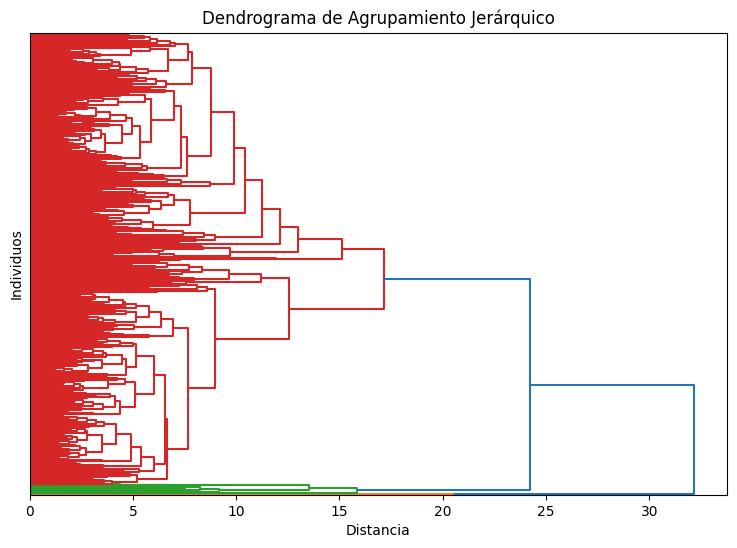

In [61]:
# Realizamos el clustering jerárquico
Z = linkage(X_escalado, method='complete')

# Calcular el dendrograma
plt.figure(figsize=(9, 6))
dendrogram(
    Z,
    orientation='right',
    no_labels=True
)

plt.title("Dendrograma de Agrupamiento Jerárquico")
plt.xlabel("Distancia")
plt.ylabel("Individuos")
plt.show()

Se selecciono la distancia de corte en 20, porque dentro de todo no limitabamos a muy pocos grupos, pero tampoco se caía en tener demasiados clústeres que no nos den nada de información

---
## <font color='264CC7'> Asignación de grupos y análisis </font>


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis de los grupos obtenidos.
<ul>
  <li>Asigna los grupos.</li>
  <li>Revisa la media de cada grupo.</li>
  <li>Revisa el mínimo y máximo de cada grupo.</li>
  <li>Muestra algunos integrantes de cada grupo.</li>
</ul>
</div>

In [64]:
# Definir la distancia de corte
distancia_corte =  16

# Asignar los grupos
clusters = fcluster(Z, t=distancia_corte, criterion='distance')

# Agregar la información de clúster
data['Cluster'] = ['C' + str(c) for c in clusters]

# Mostrar los primeros registros
display(data.head())

,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Cluster
0,122.0,127.3,20,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,C5
1,160.0,142.5,19,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,C4
2,122.0,124.8,19,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,C5
3,122.0,119.6,20,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,C5
4,100.0,141.5,45,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,C5


In [65]:
# Cantidad de elementos por grupo
data['Cluster'].value_counts()

,count
Cluster,
C5,2173
C4,2152
C3,83
C2,13
C1,3


In [66]:
# Revisar las medias de cada grupo
data.groupby('Cluster').mean()

,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
Cluster,,,,,,,,,,,,,,,,,,
C1,133.666667,137.400000,25.000000,12.000000,19.000000,41.000000,18.000000,13.088889,11.333333,10.333333,15.666667,28.666667,14.333333,12.941148,7.666667,12.866667,2.733333,-2.600000
C2,131.161538,128.192308,28.923077,1.461538,8.692308,10.384615,1.846154,4.148859,7.000000,1.230769,8.692308,10.461538,1.923077,3.764243,7.307692,11.753846,0.200000,-1.745385
C3,130.468675,126.003614,30.590361,12.759036,16.662651,20.638554,15.156627,12.344363,0.542169,11.012048,14.132530,16.879518,12.879518,12.461426,0.289157,12.224096,1.650602,-1.421928
C4,136.978113,131.600558,22.031599,0.820167,6.776952,8.796004,5.971190,12.980229,0.039963,0.593866,6.748606,8.667286,5.820632,12.973053,0.037639,11.739452,1.439452,0.019461
C5,128.379844,122.415923,24.170732,0.120571,5.340083,7.277957,3.053843,8.294412,0.162448,0.072711,5.391164,7.085596,2.743212,7.463581,0.203405,11.366452,1.006581,0.053079


In [67]:
# Revisar los valores mínimos de cada grupo
data.groupby('Cluster').min()

,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
Cluster,,,,,,,,,,,,,,,,,,
C1,110.0,117.2,21,11,18,33,18,11.833333,10,9,13,26,12,11.428571,5,7.6,2.6,-4.06
C2,110.0,110.0,18,0,6,7,0,0.000000,5,0,6,7,0,0.000000,4,7.6,-0.8,-4.06
C3,100.0,100.0,18,5,11,13,8,10.214286,0,4,8,8,8,10.666667,0,7.6,-0.8,-4.06
C4,100.0,95.0,17,0,2,2,1,10.000000,0,0,4,4,1,10.000000,0,7.6,-0.8,-4.06
C5,95.0,95.0,17,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,7.6,-0.8,-4.06


In [68]:
# Revisar los valores máximos de cada grupo
data.groupby('Cluster').max()

,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
Cluster,,,,,,,,,,,,,,,,,,
C1,150.0,150.0,28,13,21,45,18,14.933333,12,12,21,33,18,14.933333,12,15.5,2.8,0.32
C2,150.0,156.5,53,7,14,22,14,15.000000,8,6,14,22,14,13.670000,12,16.2,2.8,1.74
C3,168.0,160.0,60,20,26,36,26,15.444444,6,19,23,28,20,15.307692,3,16.2,3.7,3.51
C4,182.0,190.0,55,13,17,25,16,18.875000,3,11,14,27,13,17.714286,3,16.2,3.7,3.51
C5,190.0,190.0,70,7,10,21,8,18.000000,6,5,10,21,8,18.571429,8,16.2,3.7,3.51


In [69]:
# Construir un DataFrame con los grupos asignados
data_grupos = data.copy()
data_grupos['Grupo'] = clusters

# Cantidad de estudiantes por grupo
print("Cantidad de estudiantes por grupo:")
display(data_grupos['Grupo'].value_counts().sort_index())

# Media de las variables por grupo (seleccionando solo columnas numéricas)
print("Media de las variables por grupo:")
medias_grupos = data_grupos.select_dtypes(include=[np.number]).groupby(data_grupos['Grupo']).mean().round(2)
display(medias_grupos)

# Valores mínimos por grupo
print("Mínimos por grupo:")
minimos_grupos = data_grupos.select_dtypes(include=[np.number]).groupby(data_grupos['Grupo']).min().round(2)
display(minimos_grupos)

# Valores máximos por grupo
print("Máximos por grupo:")
maximos_grupos = data_grupos.select_dtypes(include=[np.number]).groupby(data_grupos['Grupo']).max().round(2)
display(maximos_grupos)

Cantidad de estudiantes por grupo:


,count
Grupo,
1,3
2,13
3,83
4,2152
5,2173


Media de las variables por grupo:


,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Grupo
Grupo,,,,,,,,,,,,,,,,,,,
1,133.67,137.40,25.00,12.00,19.00,41.00,18.00,13.09,11.33,10.33,15.67,28.67,14.33,12.94,7.67,12.87,2.73,-2.60,1.0
2,131.16,128.19,28.92,1.46,8.69,10.38,1.85,4.15,7.00,1.23,8.69,10.46,1.92,3.76,7.31,11.75,0.20,-1.75,2.0
3,130.47,126.00,30.59,12.76,16.66,20.64,15.16,12.34,0.54,11.01,14.13,16.88,12.88,12.46,0.29,12.22,1.65,-1.42,3.0
4,136.98,131.60,22.03,0.82,6.78,8.80,5.97,12.98,0.04,0.59,6.75,8.67,5.82,12.97,0.04,11.74,1.44,0.02,4.0
5,128.38,122.42,24.17,0.12,5.34,7.28,3.05,8.29,0.16,0.07,5.39,7.09,2.74,7.46,0.20,11.37,1.01,0.05,5.0


Mínimos por grupo:


,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Grupo
Grupo,,,,,,,,,,,,,,,,,,,
1,110.0,117.2,21,11,18,33,18,11.83,10,9,13,26,12,11.43,5,7.6,2.6,-4.06,1
2,110.0,110.0,18,0,6,7,0,0.00,5,0,6,7,0,0.00,4,7.6,-0.8,-4.06,2
3,100.0,100.0,18,5,11,13,8,10.21,0,4,8,8,8,10.67,0,7.6,-0.8,-4.06,3
4,100.0,95.0,17,0,2,2,1,10.00,0,0,4,4,1,10.00,0,7.6,-0.8,-4.06,4
5,95.0,95.0,17,0,0,0,0,0.00,0,0,0,0,0,0.00,0,7.6,-0.8,-4.06,5


Máximos por grupo:


,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Grupo
Grupo,,,,,,,,,,,,,,,,,,,
1,150.0,150.0,28,13,21,45,18,14.93,12,12,21,33,18,14.93,12,15.5,2.8,0.32,1
2,150.0,156.5,53,7,14,22,14,15.00,8,6,14,22,14,13.67,12,16.2,2.8,1.74,2
3,168.0,160.0,60,20,26,36,26,15.44,6,19,23,28,20,15.31,3,16.2,3.7,3.51,3
4,182.0,190.0,55,13,17,25,16,18.88,3,11,14,27,13,17.71,3,16.2,3.7,3.51,4
5,190.0,190.0,70,7,10,21,8,18.00,6,5,10,21,8,18.57,8,16.2,3.7,3.51,5


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Da una descripción de los grupos obtenidos. Asigna un nombre a cada grupo.
</div>

### Descripción de los grupos

**Grupo 1: Estudiantes con alto avance académico**

Este grupo está conformado por 3 estudiantes que destacan por la cantidad de unidades curriculares aprobadas: 18 en el primer semestre y 14,33 en el segundo. Sus calificaciones medias son de 13,09 y 12,94, respectivamente, lo que refleja un desempeño relativamente estable.

**Grupo 2: Estudiantes con bajo rendimiento académico**

Está integrado por 13 estudiantes que presentan un bajo número de unidades aprobadas y calificaciones medias de 4,15 en el primer semestre y 3,76 en el segundo. Además, registran una cantidad elevada de unidades sin evaluación.

**Grupo 3: Estudiantes con rendimiento académico favorable**

Este grupo reúne a 83 estudiantes que mantienen un desempeño favorable, con 15,16 unidades aprobadas en el primer semestre y 12,88 en el segundo. Sus calificaciones medias son de 12,34 y 12,46, mostrando estabilidad entre ambos períodos.

**Grupo 4: Estudiantes con avance académico moderado**

Con 2.152 estudiantes, este grupo presenta un promedio de 5,97 unidades aprobadas en el primer semestre y 5,82 en el segundo. A pesar de aprobar una cantidad moderada de unidades, mantiene calificaciones medias cercanas a 13 en ambos períodos.

**Grupo 5: Estudiantes con menor avance académico**

Es el grupo más numeroso, con 2.173 estudiantes. Se caracteriza por un menor número de unidades aprobadas, con promedios de 3,05 en el primer semestre y 2,74 en el segundo. Sus calificaciones medias también son inferiores a las del Grupo 4, con 8,29 y 7,46, respectivamente.

**Conclusión:** Los grupos presentan diferencias principalmente en la cantidad de unidades curriculares aprobadas y las calificaciones obtenidas. Se identifican perfiles minoritarios con desempeños académicos particulares y dos grupos predominantes que reúnen a la mayor parte de los estudiantes, pero que presentan diferencias en su avance y rendimiento académico.

---
## <font color='264CC7'> Visualizaciones  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una visualización de los grupos obtenidos en 2D.
<ul>
  <li>¿Qué tan buenos te parecen los grupos?</li>
  <li>Indica el porcentaje de la variaza explicada en el gráfico, ¿afecta esto a tu visualización?</li>
</ul>
</div>

In [70]:
# Realizar PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_escalado)

# Crear un DataFrame para graficar
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])

# Agregar los grupos
df_pca['Cluster'] = data['Cluster'].values

# Crear el gráfico
fig = px.scatter(
    df_pca,
    x='PC1',
    y='PC2',
    color='Cluster'
)

# Personalizar apariencia
fig.update_traces(marker=dict(opacity=0.8))

fig.update_layout(
    title='Agrupamiento Jerárquico de Estudiantes mediante PCA',
    width=800,
    height=600
)

fig.show()

# Mostrar porcentaje de varianza explicada
print("Varianza explicada por PC1:",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("Varianza explicada por PC2:",
      round(pca.explained_variance_ratio_[1] * 100, 2), "%")

print("Varianza explicada acumulada:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

Varianza explicada por PC1: 34.29 %
Varianza explicada por PC2: 12.52 %
Varianza explicada acumulada: 46.81 %


Claramente afecta el porcentaje de varianza explicada al gráfico ya que solo nos limitamos a 2 componentes que no explican ni el 50% de la varianza completa. Sin embargo, como herramienta para poder visualizar los clústeres en 2 dimensiones esto nos permite ver que hay algunos grupos de datos atipicos que estan muy separados del resto y por ello hay clústeres con tan pocos datos y hay otros 2 grupos de muchos estudiantes los cuales estan con bastante superposición.

---
## <font color='264CC7'> Métricas  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Calcula la métrica de la silueta para los grupos obtenidos. ¿Qué tan buenos te parecen los grupos?
</div>

In [71]:
# Calcular la métrica de silueta
silueta = silhouette_score(X_escalado, clusters)

print("Coeficiente de silueta:", round(silueta, 4))

Coeficiente de silueta: 0.103


Como el coeficiente es 0.103 se puede decir que el agrupamiento aunque no es 100% malo si existe una fuerte superposición entre los dos principales grupos que acumulan la mayoría de los datos

---
## <font color='264CC7'> Iteraciones </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza el proceso de agrupamiento jerárquico con diferentes parámetros, analiza la métrica de la silueta de cada uno e indica cuál es el mejor.
</div>

In [73]:
# Métodos de enlace que vamos a comparar
metodos = ['single', 'complete', 'average', 'ward']

# Guardar los resultados
resultados = []

# Realizar el agrupamiento con cada método
for metodo in metodos:

    Z = linkage(X_escalado, method=metodo)

    clusters_iter = fcluster(Z, t=5, criterion='maxclust')

    # Calcular la silueta
    silueta = silhouette_score(X_escalado, clusters_iter)

    resultados.append([metodo, round(silueta, 4)])

# Mostrar los resultados
df_resultados = pd.DataFrame(
    resultados,
    columns=['Método', 'Silueta']
)

display(df_resultados)

,Método,Silueta
0,single,0.5967
1,complete,0.1030
2,average,0.5836
3,ward,0.1617


Se observa que con el método single se obtiene el coeficiente de silueta más grande con un valor de 0.59, lo que es una mejora sustantiva al coeficiente que se obtuvo con el método complete de 0.1